## Teste Z
Máquina fabrica perfumes com média μ = 150 ml e desvio padrão 𝜎 = 2 ml. Uma amostra aleatória de 100 frascos de perfume é colhida e observa-se uma média de 150,2 ml. A máquina está operando corretamente (confiança = 95%)?

In [4]:
import pandas as pd
import numpy as np
import seaborn as sns

import scipy.stats as stats
from statsmodels.stats import weightstats

Vamos agora plotar a distribuição desses dados usando displot.

In [5]:
df = pd.read_csv('Machine1.csv')
df

,Machine 1
0,152.63
1,152.94
2,151.29
3,153.44
4,148.58
...,...
95,150.03
96,146.79
97,150.02
98,146.42


In [ ]:
sns.displot(data=df,)

Vamos plotar um boxplot dos nossos dados.

<Axes: >

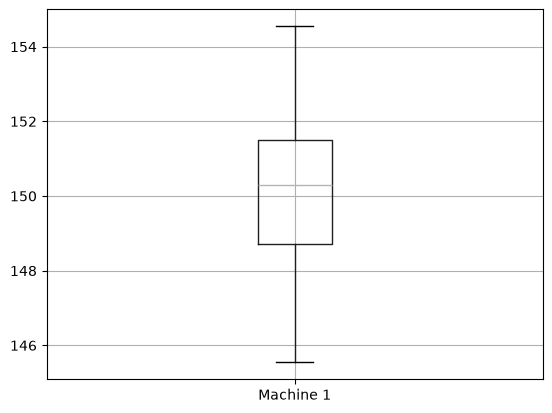

In [6]:
df.boxplot(column=['Machine 1'])

Para realizar nosso teste de hipótese (Teste Z) vamos usar weightstats.

H0: μ = 150 ml \
HA: μ <> 150 ml

In [ ]:
weightstats.ztest(x1=df['Machine 1'], value=150, alternative='two-sided')


#x1 onde tenho os dados de cada uma das amostras
#média conhecida
#alternative-. quantas caldas, default two

#analisando p value em relação à alfa

(np.float64(1.0060370247722599), np.float64(0.3143977600779597))

Conclusão: 
Tendo em vista que p value é 0.31, logo é maior que 0.0005! falamos em rejeitar a hipótese nula. assim, a máquia está operando corretamente. ç

## Teste t
Máquina fabrica perfumes com média μ = 150 ml. Uma amostra aleatória de 4 frascos de perfume é colhida e observa-se uma média de 151 ml e um desvio padrão amostral s = 2 ml. A máquina está operando corretamente (confiança = 95%)?

H0: μ = 150 ml \
HA: μ <> 150 ml

Vamos começar gerando as 4 amostras.

In [13]:
volume = pd.Series([148.5, 153.4, 150.9, 151.2])
volume

0    148.5
1    153.4
2    150.9
3    151.2
dtype: float64

In [14]:
volume.describe()

count      4.000000
mean     151.000000
std        2.004994
min      148.500000
25%      150.300000
50%      151.050000
75%      151.750000
max      153.400000
dtype: float64

Vamos agora realizar o Teste t.

H0: μ = 150 ml \
HA: μ <> 150 ml

In [ ]:
stats.ttest_1samp(volume, 150)
#teste de uma amostra

#valor estatístico é quase 1, o t calculado
#p value é 0.39
#os graus de liberdade é 3

TtestResult(statistic=np.float64(0.997509336107632), pvalue=np.float64(0.3920333832606524), df=np.int64(3))

Conclusão: é a mesma da outra

Exercício 1 \
Suponha que uma máquina envase garrafas de vinho com média 750 ml e desvio padrão desconhecido. A vinícola decidiu realizar um teste de hipótese com erro alfa = 0,05 e duas caudas. Para tanto, escolheu 4 amostras do arquivo Machine2.csv. Realize o teste t e informe se a máquina está operando corretamente (hipótese nula).

H0: μ = 750 ml
Ha: μ ≠ 750 ml

In [21]:
df = pd.read_csv('Machine2.csv')
media_amostras = df['Machine 2'].head(4)


stats.ttest_1samp(media_amostras, 750)


TtestResult(statistic=np.float64(1.0342557374997143), pvalue=np.float64(0.37707877575098303), df=np.int64(3))

Conclusão: é  mesmaaaaaaaaaaaaaaaa


Exercício 2 \
Suponha que o desvio padrão da máquina seja conhecido (15 ml). Realize um teste Z com as 50 amostras disponíveis no arquivo 'machine2.csv'.

In [22]:
weightstats.ztest(x1=df['Machine 2'], value= 750)

(np.float64(0.9804661150943946), np.float64(0.32685608794791343))

Conclusão: